DNA stores instructions, but DNA itself does nothing. The work of a cell is done mostly by **proteins**. This chapter follows the path from one to the other, which Francis Crick called the **central dogma** of molecular biology:

**DNA → (transcription) → RNA → (translation) → protein**

Every later topic depends on it. RNA-seq (chapter 6) measures the middle step. Mutations matter because of the last step. mRNA vaccines and many cancer drugs work by hijacking one of the steps.

:::eli5
The DNA in the nucleus is a precious reference book that never leaves the library. When the cell needs a tool, it photocopies one page (a gene) onto a cheap, disposable sheet: **messenger RNA**. The copy is taken to a workshop (the **ribosome**), which reads the letters three at a time and, for each three-letter word, adds one bead (an **amino acid**) to a growing chain. The finished chain folds up into a tool: a **protein**.
:::

## Step 1: transcription, DNA → RNA

A gene is copied into RNA by the enzyme **RNA polymerase**. It binds at the gene's **promoter**, unwinds a short stretch of the double helix, and builds an RNA strand complementary to one DNA strand (the **template strand**). The RNA therefore has the same sequence as the *other* strand (the **coding strand**), with U in place of T. That is why gene sequences in databases are given as the coding strand: to get the RNA, just swap T for U.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from collections import Counter

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

COMP = {"A": "T", "T": "A", "G": "C", "C": "G"}
def revcomp(seq):
    return "".join(COMP[b] for b in reversed(seq))

coding = "ATGGTGCATCTGACTCCTGAGGAG"           # start of the human HBB gene (coding strand)
template = revcomp(coding)                   # the strand RNA polymerase actually reads
mrna = coding.replace("T", "U")
print("coding strand   5′", coding, "3′")
print("template strand 3′", template[::-1], "5′")
print("mRNA            5′", mrna, "3′")

coding strand   5′ ATGGTGCATCTGACTCCTGAGGAG 3′
template strand 3′ TACCACGTAGACTGAGGACTCCTC 5′
mRNA            5′ AUGGUGCAUCUGACUCCUGAGGAG 3′


In human cells, RNA polymerase II moves at roughly 2–4 kilobases per minute. Three pieces of processing happen while it works:

1. A **5′ cap** (a modified G) is added to the front. It protects the RNA and helps the ribosome find it.
2. A **poly-A tail** of 100–250 As is added to the end. Longer tails generally mean longer-lived messages.
3. **Splicing** removes the introns.

## Step 2: splicing, cutting out introns

Most human genes are split. The pieces that end up in the final message are **exons**; the pieces in between, the **introns**, are cut out by a large RNA–protein machine called the **spliceosome**. Introns almost always begin with `GT` and end with `AG` (the **GT–AG rule**), which is part of how the spliceosome recognises them.

Let's see this on a real gene. *HBB* encodes β-globin, half of the haemoglobin that carries oxygen in your red blood cells. We downloaded two files from NCBI: the genomic DNA of the whole gene (from chromosome 11) and the finished mRNA, annotated with where each exon is.

In [2]:
from Bio import SeqIO
mrna_rec = SeqIO.read("datasets/NM_000518.gb", "genbank")
genomic = str(SeqIO.read("datasets/HBB_genomic.fasta", "fasta").seq)
mature = str(mrna_rec.seq)
exons = [(int(f.location.start), int(f.location.end)) for f in mrna_rec.features if f.type == "exon"]
print(f"gene on chromosome 11: {len(genomic):,} bases | mature mRNA: {len(mature)} bases | exons in the mRNA: {exons}")

# find each exon inside the genomic sequence; the gaps between them are the introns
gpos = [genomic.find(mature[a:b]) for a, b in exons]
structure, prev_end = [], 0
for (a, b), g in zip(exons, gpos):
    if g > prev_end:
        structure.append(("intron", prev_end, g))
    structure.append(("exon", g, g + (b - a)))
    prev_end = g + (b - a)
for kind, s, e in structure:
    edge = f"starts {genomic[s:s + 2]} ... ends {genomic[e - 2:e]}" if kind == "intron" else ""
    print(f"{kind:6s} {s + 1:>5}–{e:<5} {e - s:>4} bases  {edge}")
intron_total = sum(e - s for k, s, e in structure if k == "intron")
R["gene_len"] = f"{len(genomic):,}"; R["mrna_len"] = len(mature); R["intron_total"] = intron_total
R["intron_pct"] = f"{intron_total / len(genomic):.0%}"

gene on chromosome 11: 1,608 bases | mature mRNA: 628 bases | exons in the mRNA: [(0, 142), (142, 365), (365, 628)]
exon       1–142    142 bases  
intron   143–272    130 bases  starts GT ... ends AG
exon     273–495    223 bases  
intron   496–1345   850 bases  starts GT ... ends AG
exon    1346–1608   263 bases  


Both introns start with `GT` and end with `AG`, exactly as the rule says. The gene is 1,608 bases long, but 980 of them (61%) are introns, so the mature mRNA is only 628 bases. *HBB* is unusually compact: across the human genome, the average gene is about 95% intron.

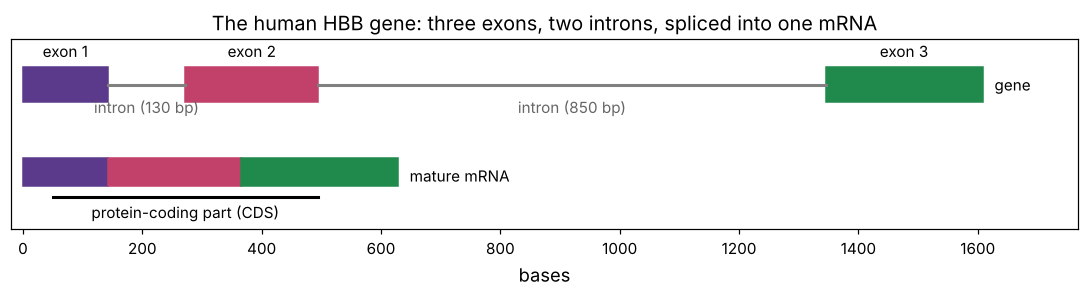

In [3]:
cds = next(f for f in mrna_rec.features if f.type == "CDS")
cds_s, cds_e = int(cds.location.start), int(cds.location.end)
fig, ax = plt.subplots(figsize=(10, 2.8))
cols = ["#5b3a8c", "#c2416b", "#1f8a4c"]; k = 0
for kind, s, e in structure:
    if kind == "exon":
        ax.add_patch(plt.Rectangle((s, 0.6), e - s, 0.5, color=cols[k])); ax.text((s + e) / 2, 1.25, f"exon {k + 1}", ha="center"); k += 1
    else:
        ax.plot([s, e], [0.85, 0.85], color="0.5", lw=2); ax.text((s + e) / 2, 0.45, f"intron ({e - s} bp)", ha="center", color="0.4", fontsize=10)
x = 0
for i, (a, b) in enumerate(exons):                          # the spliced mRNA underneath
    ax.add_patch(plt.Rectangle((x, -0.6), b - a, 0.4, color=cols[i])); x += b - a
ax.plot([cds_s, cds_e], [-0.75, -0.75], color="k", lw=2); ax.text((cds_s + cds_e) / 2, -1.05, "protein-coding part (CDS)", ha="center", fontsize=10)
ax.text(x + 20, -0.45, "mature mRNA", va="center"); ax.text(len(genomic) + 20, 0.85, "gene", va="center")
ax.set_xlim(-20, len(genomic) + 160); ax.set_ylim(-1.2, 1.5); ax.set_yticks([]); ax.set_xlabel("bases")
ax.set_title("The human HBB gene: three exons, two introns, spliced into one mRNA")
save_fig("hbb_structure"); plt.show()

![Figure P4-1. The human HBB gene drawn to scale (top) and the spliced mRNA (bottom). The black bar marks the part that is translated into protein. The rest of the mRNA is the 5′ and 3′ untranslated regions.](images/hbb_structure.png)

:::bio
Why split genes at all? One reason is **alternative splicing**: by including or skipping different exons, one gene can make several different proteins. More than 90% of human multi-exon genes are alternatively spliced, which is part of how about 20,000 genes produce a much larger variety of proteins. Mistakes in splicing cause disease, and some cancers carry mutations in the spliceosome itself (for example in the gene *SF3B1*).
:::

:::lab
Bacteria have no introns and no spliceosome. To make human insulin in *E. coli*, which is how most insulin has been made since 1982, biotechnologists first copy the *spliced* mRNA back into DNA using the viral enzyme reverse transcriptase. That intron-free copy is called **cDNA** (complementary DNA), and it is also the first step of RNA-seq (chapter 6).
:::

## Step 3: the genetic code

A protein is a chain of **amino acids**, of which there are 20 kinds. The mRNA is read in non-overlapping groups of three bases called **codons**. With 4 letters there are 4 × 4 × 4 = 64 possible codons, more than enough for 20 amino acids. So the code is **redundant** (or *degenerate*): most amino acids have several codons. Three codons (`UAA`, `UAG`, `UGA`) mean **stop**, and `AUG` both codes for methionine and marks the **start**.

The entire code fits in one 64-character string:

ATG -> M | TGG -> W | GAG -> E | GTG -> V | TAA -> *


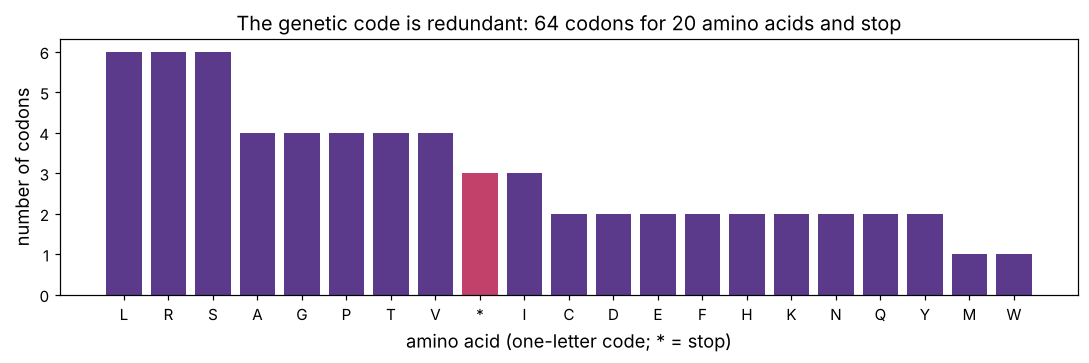

In [4]:
BASES = "TCAG"
AAS = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODE = {a + b + c: AAS[16 * i + 4 * j + k]
        for i, a in enumerate(BASES) for j, b in enumerate(BASES) for k, c in enumerate(BASES)}
print("ATG ->", CODE["ATG"], "| TGG ->", CODE["TGG"], "| GAG ->", CODE["GAG"], "| GTG ->", CODE["GTG"], "| TAA ->", CODE["TAA"])

# check against Biopython's built-in standard table
from Bio.Data import CodonTable
std = CodonTable.unambiguous_dna_by_id[1]
assert all(CODE[c] == std.forward_table.get(c, "*") for c in CODE)

per_aa = Counter(CODE.values())
order = sorted(per_aa, key=lambda a: (-per_aa[a], a))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(order, [per_aa[a] for a in order], color=["#c2416b" if a == "*" else "#5b3a8c" for a in order])
ax.set_ylabel("number of codons"); ax.set_xlabel("amino acid (one-letter code; * = stop)")
ax.set_title("The genetic code is redundant: 64 codons for 20 amino acids and stop")
save_fig("degeneracy"); plt.show()
R["six"] = ", ".join(a for a in order if per_aa[a] == 6)
R["one"] = " and ".join(a for a in order if per_aa[a] == 1)

![Figure P4-2. How many codons code for each amino acid. Leucine (L), serine (S) and arginine (R) have six each; methionine (M) and tryptophan (W) have only one.](images/degeneracy.png)

Amino acids L, R, S have six codons each; M and W have only one. The code is almost **universal**: bacteria, plants and humans use the same table, which is strong evidence that all life shares a common ancestor, and is the reason a human gene works inside *E. coli*. (A few small exceptions exist, for example inside mitochondria.)

Each amino acid has a three-letter and a one-letter abbreviation. You don't need to memorise them; the one-letter codes become familiar with use, and the table in the playground's "genetic code" tab is always there.

## Step 4: translation, RNA → protein

Translation happens on the **ribosome**, a huge machine made of RNA and protein (in fact, its catalytic core is RNA). The adaptors are **transfer RNAs** (tRNAs): small RNAs with an **anticodon** loop on one end that pairs with a codon, and the matching amino acid attached to the other end.

1. **Start.** The small ribosomal subunit binds the 5′ cap, scans along the mRNA, and stops at the first `AUG`. The large subunit joins.
2. **Elongation.** For each codon, the matching tRNA arrives, the ribosome bonds its amino acid to the growing chain (a **peptide bond**), and the ribosome moves on three bases. Human ribosomes add about 5–6 amino acids per second.
3. **Stop.** At a stop codon no tRNA fits. A **release factor** binds instead, and the finished chain is released.

Let's translate *HBB* ourselves and check the answer against NCBI's annotation:

In [5]:
def translate(dna, to_stop=True):
    protein = []
    for i in range(0, len(dna) - 2, 3):
        aa = CODE[dna[i:i + 3]]
        if aa == "*" and to_stop:
            break
        protein.append(aa)
    return "".join(protein)

cds_seq = mature[cds_s:cds_e]
prot = translate(cds_seq)
print(f"coding sequence: {len(cds_seq)} bases -> {len(prot)} amino acids, then stop codon {cds_seq[-3:]}")
print(prot)
print("matches NCBI's annotation:", prot == cds.qualifiers["translation"][0])
R["n_aa"] = len(prot)

coding sequence: 444 bases -> 147 amino acids, then stop codon TAA
MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH
matches NCBI's annotation: True


Our 15-line translator reproduces NCBI's protein exactly: 147 amino acids. (The first methionine is then trimmed off, so the mature β-globin chain is 146 long. Biologists number its positions without that methionine, which matters for the sickle-cell mutation below.)

Try it in the playground: change bases in *HBB*, see the codons shift, and switch the reading frame. The second tab is the full genetic code, and the third walks through the whole *HBB* story you just computed.

::playground animations/dogma_lab.html 620

## Reading frames and a first gene finder

A DNA sequence can be read in three frames on each strand, six in total. Only one of them (usually) is the real gene. How would you find genes in a newly sequenced genome? The simplest idea uses stop codons. Of the 64 codons, 3 are stops, so in *random* DNA a stop turns up on average every 64/3 ≈ 21 codons. A real gene must run for hundreds of codons with no stop. So a long stretch without stop codons, an **open reading frame** (ORF), is a strong hint of a gene.

Let's test the idea on phage lambda, comparing its real genome with a shuffled copy that has the same letters in random order.

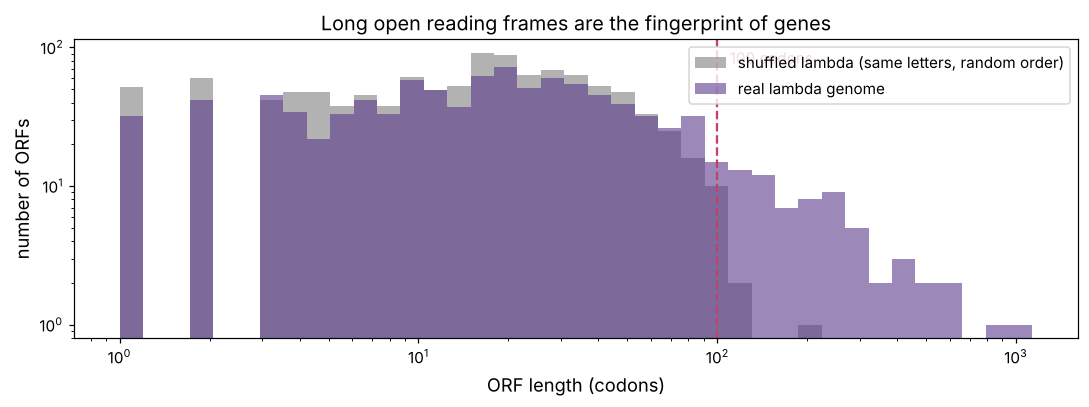

ORFs of 100+ codons: real 67, shuffled 4
longest ORF: real 1132 codons, shuffled 215 codons


In [6]:
lam = str(SeqIO.read("../03-dna/datasets/NC_001416.fasta", "fasta").seq)

def orfs(seq, min_codons=1):
    """Lengths (in codons) of all ATG...stop open reading frames on both strands, all 3 frames."""
    out = []
    for strand in (seq, revcomp(seq)):
        for f in range(3):
            start = None
            for i in range(f, len(strand) - 2, 3):
                c = strand[i:i + 3]
                if start is None and c == "ATG":
                    start = i
                elif start is not None and CODE[c] == "*":
                    if (i - start) // 3 >= min_codons:
                        out.append((i - start) // 3)
                    start = None
    return np.array(out)

rng = np.random.default_rng(0)
shuffled = "".join(rng.permutation(list(lam)))
real, rand = orfs(lam), orfs(shuffled)

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(0, np.log10(max(real.max(), rand.max()) + 1), 40)
ax.hist(rand, bins, alpha=0.6, color="0.5", label="shuffled lambda (same letters, random order)")
ax.hist(real, bins, alpha=0.6, color="#5b3a8c", label="real lambda genome")
ax.axvline(100, color="#c2416b", ls="--"); ax.text(110, ax.get_ylim()[1] * 0.8, "100 codons", color="#c2416b")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("ORF length (codons)"); ax.set_ylabel("number of ORFs")
ax.legend(); ax.set_title("Long open reading frames are the fingerprint of genes")
save_fig("orfs"); plt.show()
print(f"ORFs of 100+ codons: real {np.sum(real >= 100)}, shuffled {np.sum(rand >= 100)}")
print(f"longest ORF: real {real.max()} codons, shuffled {rand.max()} codons")
R["real100"] = int(np.sum(real >= 100)); R["rand100"] = int(np.sum(rand >= 100))
R["real_max"] = int(real.max()); R["rand_max"] = int(rand.max())

![Figure P4-3. Lengths of open reading frames (ATG to stop) in phage lambda versus a shuffled copy of the same genome, on log scales. Random sequence almost never produces long ORFs; the real genome is full of them.](images/orfs.png)

The real genome has 67 ORFs of 100 codons or more; the shuffled genome has 4. The longest real ORF is 1132 codons, against 215 in the shuffle. Lambda has about 70 genes, and long ORFs pick out most of them. (Many ORFs overlap, since they are nested or in different frames, which is why the count is not the gene count.) Simple ORF finding works well in bacteria and viruses, whose genes have no introns. In humans, where exons are short and scattered across huge introns, gene finding needs statistical models and, today, deep learning (chapter 9).

## Mutations: what a single changed letter does

A **point mutation** changes one base. What happens to the protein depends on the codon:

| Type | What changes | Typical effect |
|---|---|---|
| **Silent** (synonymous) | the codon changes but still codes the same amino acid | usually none |
| **Missense** | a different amino acid | anything from harmless to devastating |
| **Nonsense** | an amino-acid codon becomes a stop | protein cut short; gene usually lost |
| **Frameshift** | insertion or deletion of a number of bases that is not a multiple of 3 | every later codon is misread; gene lost |

The most famous missense mutation is in *HBB*. Changing codon 7 (counting the start methionine) from `GAG` to `GTG` swaps glutamate for valine. The resulting haemoglobin sticks to itself at low oxygen and bends red blood cells into a sickle shape: **sickle-cell disease**. Doctors call it "Glu6Val" because they count from after the trimmed methionine.

In [7]:
sickle = cds_seq[:19] + "T" + cds_seq[20:]
a, b = translate(cds_seq), translate(sickle)
diff = [(i + 1, x, y) for i, (x, y) in enumerate(zip(a, b)) if x != y]
print("codon 7 normal:", cds_seq[18:21], "-> sickle:", sickle[18:21], "| amino acid changes (position, from, to):", diff)

codon 7 normal: GAG -> sickle: GTG | amino acid changes (position, from, to): [(7, 'E', 'V')]


Now a census. Take every position in the *HBB* coding sequence and try all three possible substitutions, then classify each:

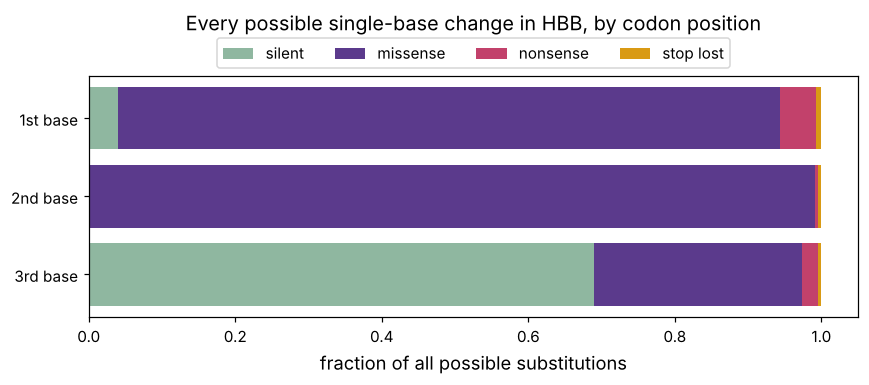

silent       325  (24.4%)
missense     966  (72.5%)
nonsense      34  (2.6%)
stop lost      7  (0.5%)


In [8]:
def classify(ref, alt):
    pa, pb = translate(ref, to_stop=False), translate(alt, to_stop=False)
    if pa == pb:
        return "silent"
    i = next(k for k in range(len(pa)) if pa[k] != pb[k])
    return "nonsense" if pb[i] == "*" else ("stop lost" if pa[i] == "*" else "missense")

counts = {p: Counter() for p in (1, 2, 3)}
for i, base in enumerate(cds_seq):
    for alt in "ACGT":
        if alt != base:
            counts[i % 3 + 1][classify(cds_seq, cds_seq[:i] + alt + cds_seq[i + 1:])] += 1

kinds = ["silent", "missense", "nonsense", "stop lost"]
colors = {"silent": "#8fb7a0", "missense": "#5b3a8c", "nonsense": "#c2416b", "stop lost": "#d99a14"}
fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(3)
for k in kinds:
    v = np.array([counts[p][k] / sum(counts[p].values()) for p in (1, 2, 3)])
    ax.barh(["1st base", "2nd base", "3rd base"], v, left=left, color=colors[k], label=k); left += v
ax.invert_yaxis(); ax.set_xlabel("fraction of all possible substitutions"); ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Every possible single-base change in HBB, by codon position", pad=30)
save_fig("mutation_census"); plt.show()
total = sum(counts.values(), Counter())
n = sum(total.values())
for k in kinds:
    print(f"{k:10s} {total[k]:5d}  ({total[k] / n:.1%})")
R["n_subs"] = n; R["silent_all"] = f"{total['silent'] / n:.0%}"
R["silent3"] = f"{counts[3]['silent'] / sum(counts[3].values()):.0%}"
R["silent2"] = f"{counts[2]['silent'] / sum(counts[2].values()):.0%}"
R["nonsense"] = f"{total['nonsense'] / n:.1%}"

![Figure P4-4. All possible single-base substitutions in the HBB coding sequence, split by position within the codon. Changes at the third base are often silent; changes at the second base almost never are (the only exceptions swap one stop codon for another).](images/mutation_census.png)

Of the 1332 possible substitutions, 24% are silent, but the split by codon position is striking: 69% of third-base changes are silent and 0% of second-base changes. The genetic code is arranged so that the most common errors do the least harm, and similar codons tend to code for chemically similar amino acids. About 2.6% of changes create a stop codon.

This census is the starting point of real tools. Cancer genomics (chapter 20) compares the numbers of silent and missense mutations in each gene: a gene with far more missense mutations than expected by chance is probably being **selected** in tumours, which flags it as a cancer driver. The calculation you just did is how that "expected by chance" is computed.

## How long does it all take?

In [9]:
pol2 = 3000 / 60             # RNA polymerase II, bases per second (about 3 kb per minute)
ribo = 6                     # amino acids per second (human ribosome)
genes = {"HBB (β-globin)": (len(genomic), len(prot)),
         "TP53": (25_800, 393),
         "titin (largest human protein)": (281_000, 34_350),
         "dystrophin (largest human gene)": (2_220_000, 3_685)}
for g, (gene_bp, aa) in genes.items():
    print(f"{g:32s} transcribe {gene_bp / pol2 / 60:7.1f} min   translate {aa / ribo / 60:5.1f} min")
R["dmd_h"] = f"{2_220_000 / pol2 / 3600:.0f}"

HBB (β-globin)                   transcribe     0.5 min   translate   0.4 min
TP53                             transcribe     8.6 min   translate   1.1 min
titin (largest human protein)    transcribe    93.7 min   translate  95.4 min
dystrophin (largest human gene)  transcribe   740.0 min   translate  10.2 min


A small gene like *HBB* is transcribed in well under a minute. The dystrophin gene (mutated in Duchenne muscular dystrophy), at 2.2 million bases, takes about 12 hours to transcribe once, almost all of it intron. Translation is quicker per molecule, and many ribosomes read one mRNA at the same time, so a single message can make thousands of protein copies. mRNAs typically last minutes to hours before being destroyed, so the cell can change its protein output quickly by changing which genes it transcribes. That control is the subject of chapter P6.

:::idea
The amount of each protein in a cell depends on every step: how often the gene is transcribed, how the RNA is spliced, how long the mRNA survives, how efficiently it is translated, and how long the protein lasts. RNA-seq measures only mRNA levels, which is why mRNA and protein levels in the same cells agree only moderately. Keep that in mind when you interpret omics data in Part 2.
:::

## Not all RNA is messenger RNA

| RNA | Role |
|---|---|
| **mRNA** (messenger) | carries a gene's code to the ribosome |
| **rRNA** (ribosomal) | forms the core of the ribosome; about 80% of a cell's RNA |
| **tRNA** (transfer) | adaptors that bring amino acids to the ribosome |
| **miRNA** (micro) | 22-base RNAs that silence matching mRNAs |
| **lncRNA** (long non-coding) | regulate genes and chromatin, in ways still being worked out |

:::bio
**mRNA vaccines** (such as those against COVID-19) are a direct use of this chapter. The vaccine delivers a synthetic mRNA, complete with 5′ cap, UTRs and poly-A tail, that encodes the virus's spike protein. Your ribosomes translate it, and your immune system learns to recognise the protein (chapter P10). Uridine is replaced with a modified version (N1-methylpseudouridine) so the RNA does not trigger an alarm and is translated longer. The same approach is being tested for personalised cancer vaccines.
:::

## Summary

| Step | Machine | Input → output |
|---|---|---|
| Transcription | RNA polymerase | gene (DNA) → pre-mRNA |
| Processing | capping enzymes, spliceosome, poly-A polymerase | pre-mRNA → mature mRNA |
| Translation | ribosome + tRNAs | mRNA codons → amino-acid chain |

:::check
1. A coding strand reads `ATGTTTGGA`. Write the mRNA and the protein. *(AUGUUUGGA; Met-Phe-Gly.)*
2. Why can't you put a human genomic gene directly into *E. coli* and expect the right protein? *(Bacteria cannot splice, so introns would be translated; you use cDNA instead.)*
3. In random sequence, about how many codons pass between stop codons? *(About 64/3 ≈ 21.)*
4. Which is more likely to be silent: a change at the second or the third base of a codon? *(The third.)*
5. A deletion of 3 bases in a coding sequence: frameshift or not? *(Not a frameshift; one amino acid is lost and the rest is read correctly.)*
:::

:::exercise
(a) Delete one base near the start of the *HBB* coding sequence (say position 30) and translate. How long is the protein before it hits a stop? (b) Repeat for every possible deletion position. Let translation run on into the 3′ UTR if needed, since a real ribosome would. For each, count the correct amino acids made before the deletion and the "junk" amino acids made after it, before a stop. How long is the typical junk tail, and does it match the random-sequence estimate from the ORF section?
:::

<details><summary>Solution</summary>

delete position 30 -> 18 amino acids instead of 147


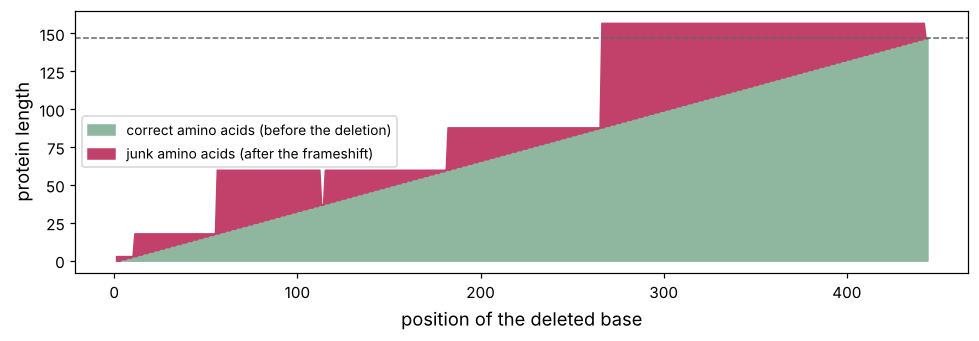

junk tail: median 22 amino acids, longest 69


In [10]:
utr3 = mature[cds_e:]
def frameshift(i):
    p = translate(cds_seq[:i] + cds_seq[i + 1:] + utr3)      # stops at the first stop codon
    return i // 3, len(p) - i // 3                            # (correct, junk)
res = np.array([frameshift(i) for i in range(len(cds_seq))])
print("delete position 30 ->", res[29].sum(), "amino acids instead of", len(prot))
fig, ax = plt.subplots(figsize=(9, 3.2))
pos = np.arange(1, len(cds_seq) + 1)
ax.fill_between(pos, 0, res[:, 0], color="#8fb7a0", label="correct amino acids (before the deletion)")
ax.fill_between(pos, res[:, 0], res.sum(1), color="#c2416b", label="junk amino acids (after the frameshift)")
ax.axhline(len(prot), color="0.4", ls="--", lw=1)
ax.set_xlabel("position of the deleted base"); ax.set_ylabel("protein length"); ax.legend(fontsize=9)
save_fig("frameshift"); plt.show()
print(f"junk tail: median {np.median(res[:, 1]):.0f} amino acids, longest {res[:, 1].max()}")

A deletion at position 30 gives a 9-amino-acid start followed by junk and a stop: 18 amino acids in total, instead of 147. Across all positions the junk tail has a median of about 22 amino acids, close to the 21-codon average gap between stops in random sequence: after a frameshift, the ribosome is effectively reading random text. The protein is lost unless the deletion falls at the very end. That is why frameshift mutations in tumour-suppressor genes such as *TP53* or *BRCA1* are almost always treated as loss of the gene.

</details>